## Problem Statement

### Context

AllLife Bank is a mid-sized, fast-growing US-based financial institution that offers a range of retail banking services, including savings and checking accounts, fixed deposits, and personal loans. The bank’s business model is centered on building long-term customer relationships, expanding its retail footprint, and growing its loan portfolio to drive sustainable profitability through interest income.

It currently relies on a large base of liability customers (depositors) but faces a significant under-representation of asset customers (borrowers). To drive profitability through interest income, the bank must aggressively expand its loan portfolio by converting existing depositors into personal loan customers.

Last year’s pilot campaign achieved a 9% conversion rate, validating the potential of this strategy. However, to optimize marketing spend and improve efficiency, the retail marketing department requires a more data-driven approach. Enhancing the success ratio of these campaigns is critical for sustainable growth and maximizing customer lifetime value.

### Objective

The objective is to develop a predictive classification model that identifies patterns and key factors driving personal loan adoption among existing liability customers. By uncovering the demographic and behavioral drivers of loan conversion, the goal is to enable targeted segmentation and more precise marketing interventions that improve campaign conversion rates, optimize marketing spend, and enhance overall profitability through higher-quality loan portfolio growth.

### Data Dictionary

* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 sklearn-pandas==2.2.0 -q --user

**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the dataset

In [ ]:
#Load this first to get the google drive mounted (needs permissions - grant ok and hit continue)
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#data csv is loaded on my google drive, called Loan_Modelling.csv so from google.colab mount drive and import path
#this is my personal data path drive - so the one for the grader of this project will be different
path = '/content/drive/MyDrive/ColabNotebooks/Loan_Modelling.csv'

In [ ]:
#import the csv from my google drive above to DF
df = pd.read_csv(path)

## Data Overview

* Observations
* Sanity checks

For Observations, we are going to look at the
Structural and Statistical overview of the data
1. Check data dimensions (rows, columns)
2. View Column names, non-null counts and data types
3. Preview the first five rows of the data
4. Summarize the stats with numerical features

In [ ]:
#check data dimensions (rows, columns)
df.shape

(5000, 14)

We have 5,000 rows of data and 14 columns

In [ ]:
#view columns, non-nulls and types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


All the columns are int64 except for CCAvg which is float64. From this it appears there is no null data.

In [ ]:
#read in the first five rows of the data
df.head()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [ ]:
#give a summary of the data with features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIPCode,5000.0,93169.257000,1759.455086,90005.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal_Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


**Observations:**

The size of the total volume of data is 5,000 rows by 14 columns, a data set whose scale is manageable. I believe that this data can be trained with this volume.

The data consists almost entirely of Int values, except for CCAvg, which is float.

We will need to encode Eduction.



For Sanity Checks, we will look at:
1. Missing Values
2. Duplicate Values
3. Unique Value Counts



In [ ]:
#Are there any missing values? Use insa and isnull to check
print(df.isna().sum())
print(df.isnull().sum())

ID                    0
Age                   0
Experience            0
Income                0
ZIPCode               0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
dtype: int64
ID                    0
Age                   0
Experience            0
Income                0
ZIPCode               0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
dtype: int64


There are no nulls or missing values. If there were, we would run this code to find them in order to treat them:

In [ ]:
#IF there were missing values, we would use this to calculate missing counts and percentages
missing_counts = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

#Make a new df to hold what is found
missing_df = pd.concat([missing_counts, missing_pct], axis=1)
missing_df.columns = ['Missing Count', 'Percentage (%)']

# Filter out clean columns and sort by highest missing value
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("Columns with missing values:")
print(missing_df.round(2))

Columns with missing values:
Empty DataFrame
Columns: [Missing Count, Percentage (%)]
Index: []


In [ ]:
#Check for duplicated rows
duplicate_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_count}")

Total duplicate rows: 0


In [ ]:
#We want to check for any data abnormalities - especially in the Income, CCAvg, Age, Experience, Personal Loan, CreditCard and Education columns
negative_income = (df['Income'] < 0).sum()
negative_ccavg = (df['CCAvg'] < 0).sum()
negative_age = (df['Age'] < 0).sum()
negative_exp = (df['Experience'] < 0).sum()
negative_edu = (df['Education'] < 0).sum()
negative_family = (df['Family'] < 0).sum()
negative_creditcard = (df['CreditCard'] < 0).sum()
negative_personalloan = (df['Personal_Loan'] < 0).sum()
print(f"--- Negative Values Anomaly Detection ---")
print(f"Rows with negative 'Income' values: {negative_income}", "\n")
print(f"Rows with negative 'CC Average' values: {negative_ccavg}", "\n")
print(f"Rows with negative 'Age' values: {negative_age}", "\n")
print(f"Rows with negative 'Experience' values: {negative_exp}", "\n")
print(f"Rows with negative 'Education' values: {negative_edu}", "\n")
print(f"Rows with negative 'Family' values: {negative_family}", "\n")
print(f"Rows with negative 'CreditCard' values: {negative_creditcard}", "\n")
print(f"Rows with negative 'Personal Loan' values: {negative_personalloan}", "\n")

--- Negative Values Anomaly Detection ---
Rows with negative 'Income' values: 0 

Rows with negative 'CC Average' values: 0 

Rows with negative 'Age' values: 0 

Rows with negative 'Experience' values: 52 

Rows with negative 'Education' values: 0 

Rows with negative 'Family' values: 0 

Rows with negative 'CreditCard' values: 0 

Rows with negative 'Personal Loan' values: 0 



We see that Experience has 52 negative values, which is an abnormality, as experience must start at 0. We will fix this when we are splitting and training the data.

In [ ]:
#Unique Value Counts
print(df.nunique())

ID                    5000
Age                     45
Experience              47
Income                 162
ZIPCode                467
Family                   4
CCAvg                  108
Education                3
Mortgage               347
Personal_Loan            2
Securities_Account       2
CD_Account               2
Online                   2
CreditCard               2
dtype: int64


**SANITY CHECKS:**

It does not appear we have any missing values.

It also appears that we do not have any duplications

We found that the "Experience" column has negative values

The unique values tend to be high at the ZIPCode, and this could cause noise in our data. During EDA we will need to see if there is any correlation between zip codes and personal loans, otherwise we should drop this.

The low unique values for the other columns should mean that the distribution should not be skewed.


## Exploratory Data Analysis.

EDA is a critical step in any data project used to investigate and understand the data before model construction.

The following questions serve as a starting point to help you approach the analysis and generate initial insights:

**Questions**:
1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their education?
5. How does a customer's interest in purchasing a loan vary with their age?

**[IMPORTANT]** Beyond the Basics: Please note that these are guiding questions only. To receive full points for this rubric section, you are expected to perform a thorough analysis that goes beyond these specific questions to uncover deeper trends and relationships within the data.

Axes(0.125,0.11;0.775x0.77)


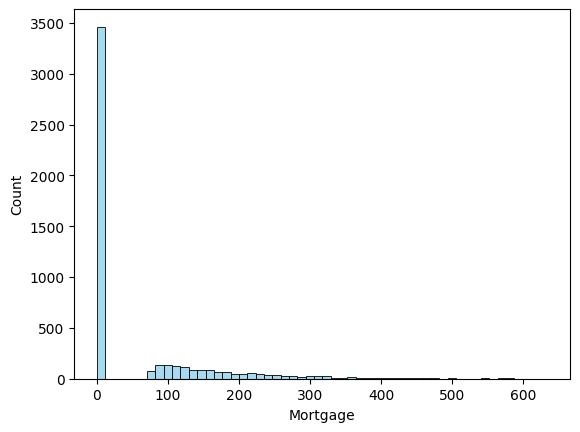

In [ ]:
#Mortgage Distribution - use histplot to review
mortdist = sns.histplot(data=df, x='Mortgage', color='skyblue')
print (mortdist)

For the mortgage distribution, we see this as right skewed with a large spike at the beginning 0.

Axes(0.125,0.11;0.775x0.77)


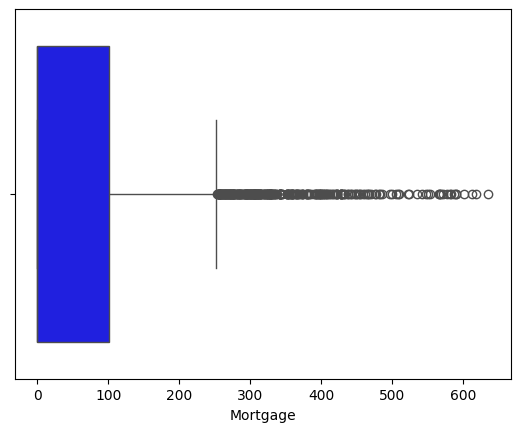

In [ ]:
#Mortgage Outliers
moutliers = sns.boxplot(data=df, x='Mortgage', color='blue')
print (moutliers)


The boxplot shows a long tail of outliers, suggesting a number of high income debts.

In [ ]:
#Does anyone have zero mortgage or no mortage with the bank?
zero_mortgage_pct = (df['Mortgage'] == 0).mean() * 100
print (zero_mortgage_pct)

69.24


The majority of customers do not have mortgages with this bank (almost 70%)


In [ ]:
#Credit card counts by person
cc_counts = df['CreditCard'].value_counts()
cc_pct = df['CreditCard'].value_counts(normalize=True) * 100

print (cc_counts, '\n', "Gives us those that have credit cards and those that don't")
print('\n')
print (cc_pct, '\n', "By percentage")

CreditCard
0    3530
1    1470
Name: count, dtype: int64 
 Gives us those that have credit cards and those that don't


CreditCard
0    70.6
1    29.4
Name: proportion, dtype: float64 
 By percentage


Roughly 30% have a credit card with this bank. This is an opportunity for selling credit cards to them.


The following Heatmap will show all the variables and allow us to see the correlations between all the data points, and determine which ones are the best to focus on.

Income                0.502462
CCAvg                 0.366889
CD_Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Securities_Account    0.021954
Online                0.006278
CreditCard            0.002802
ZIPCode              -0.002974
Experience           -0.007413
Age                  -0.007726
ID                   -0.024801
Name: Personal_Loan, dtype: float64




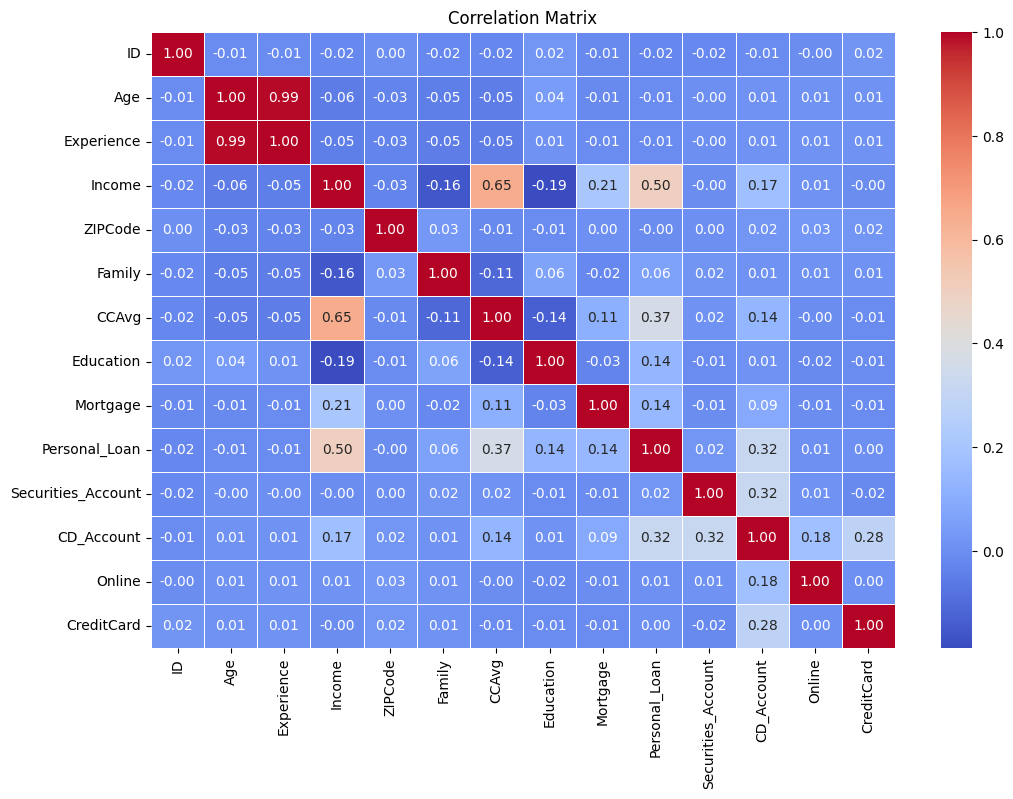

In [ ]:
#Coorelation by target (Personal_Loan) using a heatmap
target = 'Personal_Loan'
correlations = df.corr()[target].sort_values(ascending=False)
print(correlations.drop(target)) # Drop self-correlation
print("\n")

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()

The heat map shows Income and CCAvg having the strongest possibility of accepting a person loan Whereas Age and Experience show near zero.

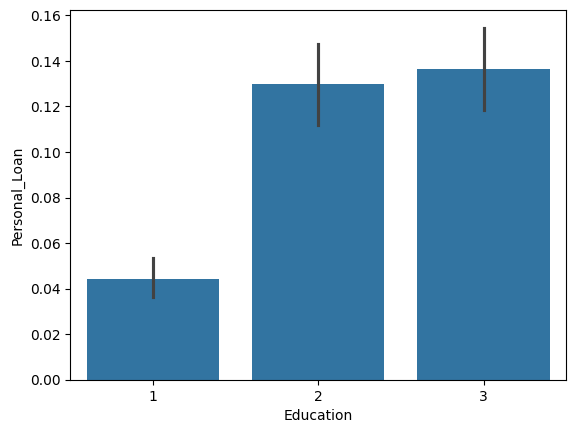

In [ ]:
# Education and Personal Loan Interest
sns.barplot(data=df, x='Education', y=target)
plt.show()

We see that the more eduction someone has (level 2, 3), the more willingness they have to take a personal loan

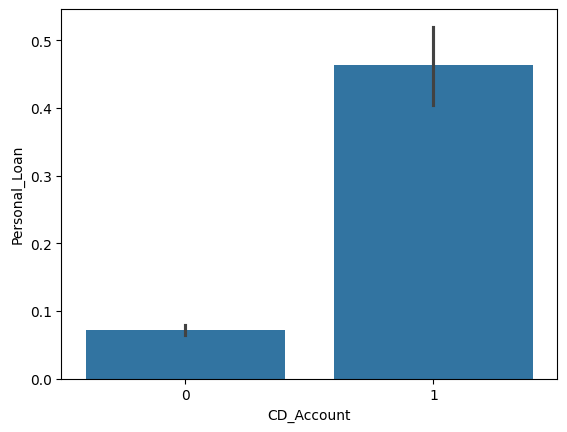

In [ ]:
# CD_Account and Personal Loan Interest
sns.barplot(data=df, x='CD_Account', y=target)
plt.show()

While customers with a CD_Account have interest, it is not very high. Lets also see what the KDEPlot shows us.

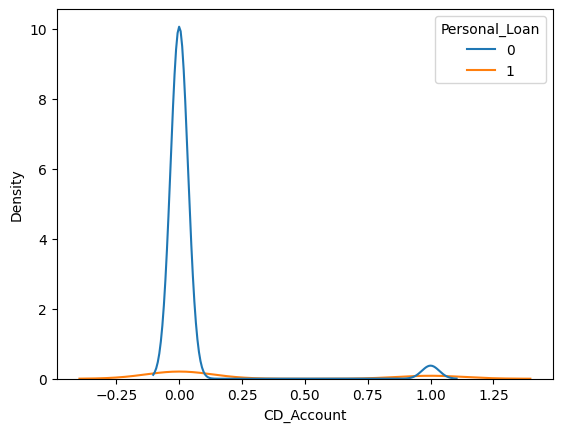

In [ ]:
# CD_Account vs Personal Loan
sns.kdeplot(data=df, x='CD_Account', hue=target)
plt.show()

This shows that CD_Account is practically 0 for personal loan.

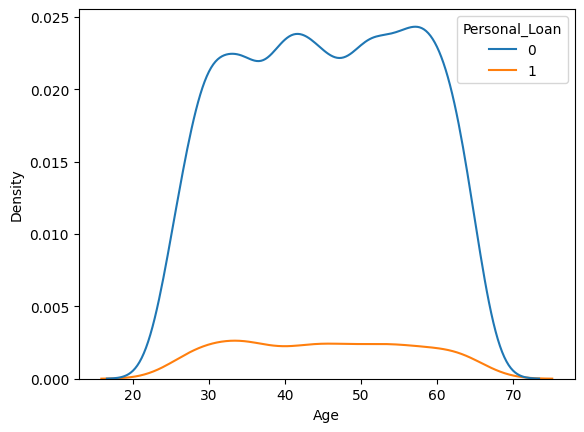

In [ ]:
# Age vs Personal Loan KDE plot
sns.kdeplot(data=df, x='Age', hue=target)
plt.show()


We see that the Age of a person is not really a factor, as the acceptance or refusal of the personal loan is pretty much equal.


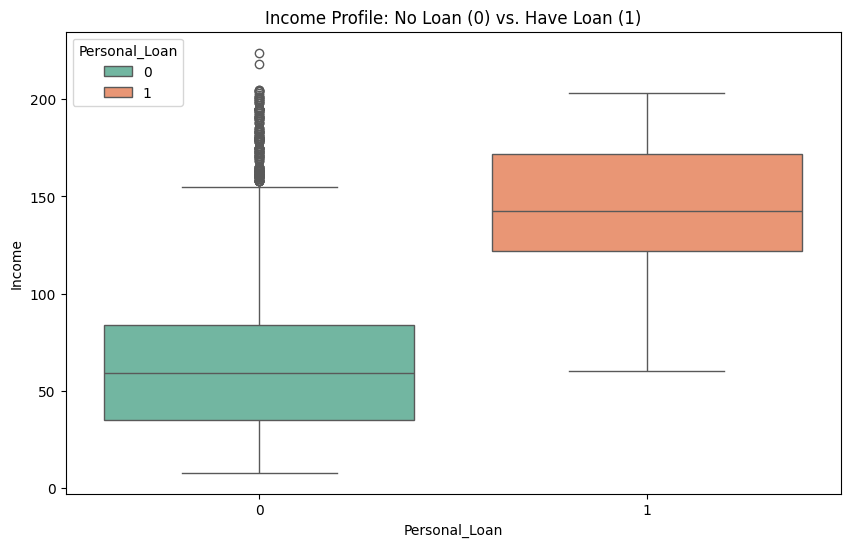

In [ ]:
#Beyond Basics: Income - reviewed as the heatmap showed this to be a strong candidate
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x=target, y='Income', palette='Set2', hue=target)
plt.title('Income Profile: No Loan (0) vs. Have Loan (1)')
plt.show()

Beyond the Basics: Our first additional review is income level, and we see that the higher the income, the more likely a personal loan is to be taken.


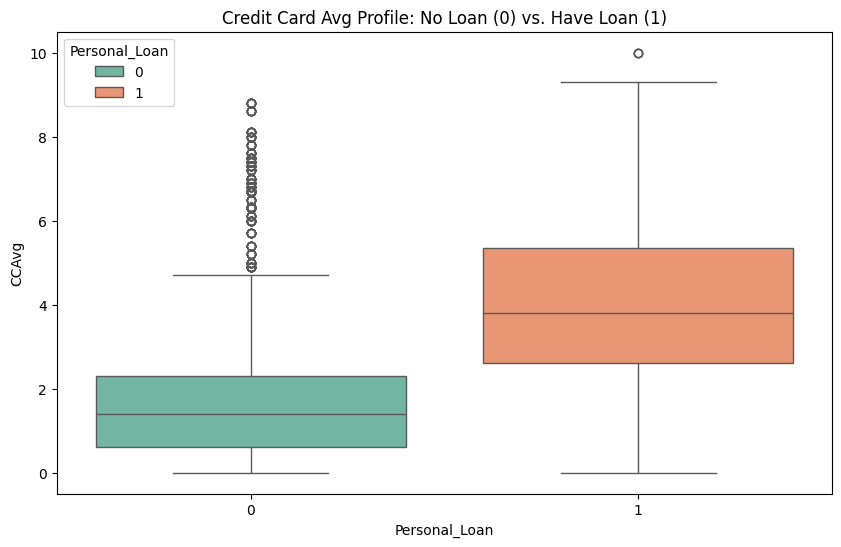

In [ ]:
#Beyond Basics: Credit Card Average - the heatmap showed this to be a strong candidate so lets see it in a boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x=target, y='CCAvg', palette='Set2', hue=target)
plt.title('Credit Card Avg Profile: No Loan (0) vs. Have Loan (1)')
plt.show()

Beyond the Basics: The second additional review shows that people that carry a credit card average are more likely to take a personal loan. This does have a number of outliers we need to look at.



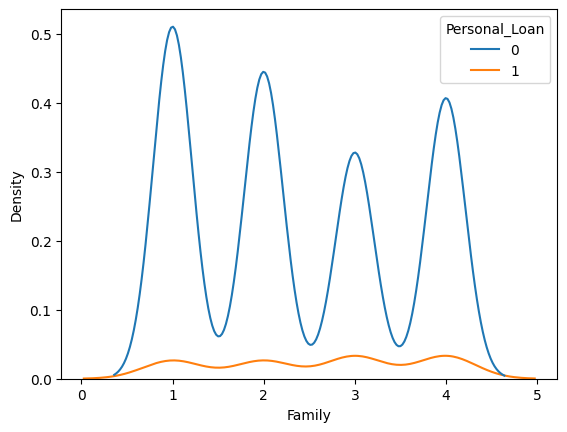

In [ ]:
#Beyond the Basics: Family vs Personal Loan
sns.kdeplot(data=df, x='Family', hue=target)
plt.show()

Beyond the Basics: I also ran a KDEPlot to show that the Heatmap's values for both Family and Online are not real factors for targeting.

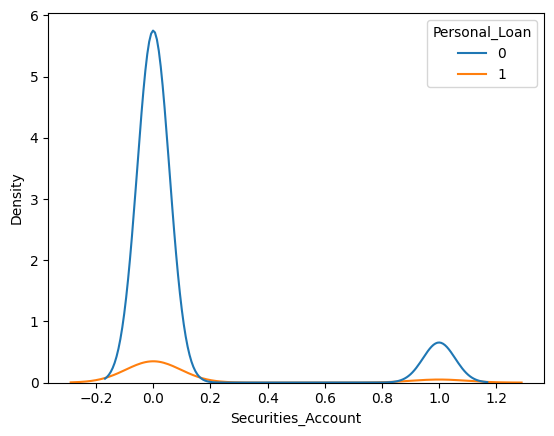

In [ ]:
# Securities_Account vs Personal Loan
sns.kdeplot(data=df, x='Securities_Account', hue=target)
plt.show()

Here we see that a customer with a securities account does not necessarily also have a personal loan

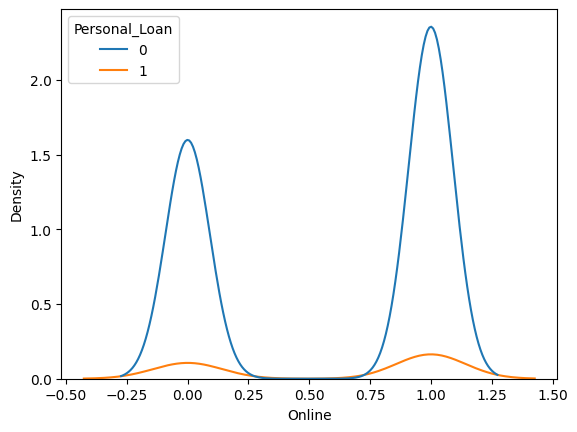

In [ ]:
# Online vs Personal Loan
sns.kdeplot(data=df, x='Online', hue=target)
plt.show()

Not a real factor, Online vs. Personal Loan

Axes(0.125,0.11;0.775x0.77)


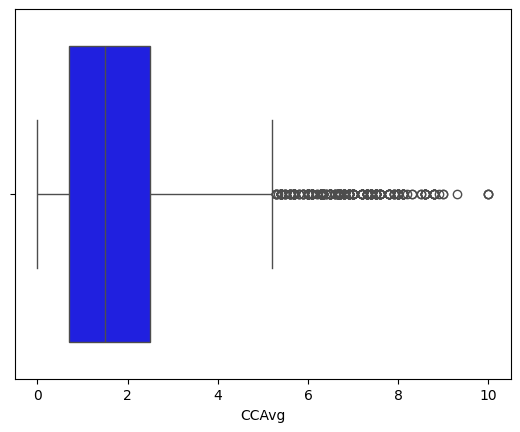

In [ ]:
#Beyond the basics: As CCAvg is an important data point, lets check for outliers:
#CCAvg Outliers
ccavgoutliers = sns.boxplot(data=df, x='CCAvg', color='blue')
print (ccavgoutliers)

We see a number of outliers for CCAvg that mean we have a large segment of high spend customers that would be ideal to market towards.

Axes(0.125,0.11;0.775x0.77)


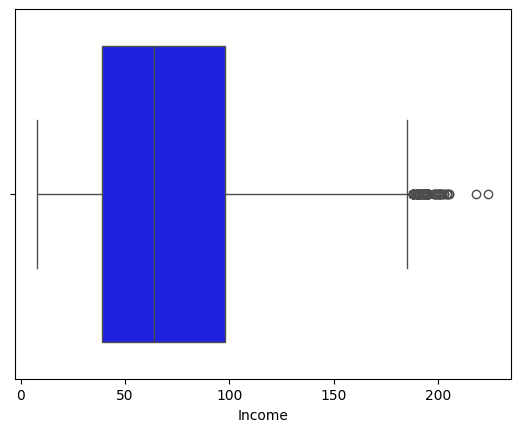

In [ ]:
#Beyond the basics: As Income is an important data point, lets check for outliers:
#Income Outliers
incomeoutliers = sns.boxplot(data=df, x='Income', color='blue')
print (incomeoutliers)

We see a number of outliers for Income that also represent opportunities to market to.

In [ ]:
#Beyond the basics: Get the exact count of customers for each education level for reference and checking for abnormalities (ie: level 5)
print(df['Education'].value_counts().sort_index())


Education
1    2096
2    1403
3    1501
Name: count, dtype: int64


We see here that Education is broken into 1, 2 and 3 levels, and no abnormalities.

In [ ]:
#Beyond the basics: Zip Codes - Take a look at what zip codes we have
print(df['ZIPCode'].value_counts().sort_index())

ZIPCode
90005    5
90007    6
90009    8
90011    3
90016    2
        ..
96091    4
96094    2
96145    1
96150    4
96651    6
Name: count, Length: 467, dtype: int64


So we have zip codes in the California/Western USA area and there are a lot of unique values. As the correlation matrix did not return any strong correlations for zip code and the other values, this may generate noise in our data if we use it.

**EXPLORATORY DATA ANALYSIS REVIEW:**

For the mortgage distribution, we see this as right skewed with a large spike at the beginning 0.
The boxplot shows a long tail of outliers, suggesting a number of high income debts.
The majority of customers do not have mortgages with this bank (almost 70%)

Roughly 30% have a credit card with this bank.
This is an opportunity for selling credit cards to them.

The heat map shows Income and CCAvg having the strongest possibility of accepting a person loan
Whereas Age and Experience show near zero.

We see that the more eduction someone has (level 2, 3), the more willingness they have to take a personal loan

We see that the Age of a person is not really a factor, as the acceptance or refusal of the personal loan is pretty much equal.

Beyond the Basics: Our first additional review is income level, and we see that the higher the income, the more likely a personal loan is to be taken.

Beyond the Basics: We see from the Heatmap that people with a CD Account may have a higher score, but our KDEplot shows they are probably not a good target as those with a CD account do not also have a personal loan.

Beyond the Basics: The second additional review shows that people that carry a  credit card average are more likely to take a personal loan.

Beyond the Basics: In our sanity check, we found that there are negative values in the Experience column, which should not have any negatives (0 would be the lowest). We should probably exclude Experience as it has this data issue, but also, experience does not have a strong indicator for wanting a personal loan.

Beyond the Basics: I also ran a KDEPlot to show that the Heatmap's values for both Family and Online are not real factors for targeting.

Beyond the Basics: We also saw that ZIPCode was based in the Western US but not really impacting our prediction and may create noise or interfer with our training, so we should probably drop this. Also, that there were no abnormalities within Education.

We see a number of outliers for CCAvg and Income, plus in our earlier review we saw outliers for Mortgage, which we will need to deal with

I believe our focus should be on individuals with Higher Income and CCAvg, as they tend to be the factors to target for new personal loans.


## Data Preprocessing

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

**Missing Value Treatment:**

It does not appear we have any missing values from our sanity checks.




In [ ]:
#Re-Confirm there are no missing values:
print(df.isna().sum())
print(df.isnull().sum())

ID                    0
Age                   0
Experience            0
Income                0
ZIPCode               0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
dtype: int64
ID                    0
Age                   0
Experience            0
Income                0
ZIPCode               0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
dtype: int64


We confirmed that there are no missing values

**Feature Engineering:**

We will scale and encode the columns when we prepare the data, please see below.


**Outlier detection and treatment**

We can see that we have outliers in Income, CCAvg and Mortgage, lets check on Education, Family and compare

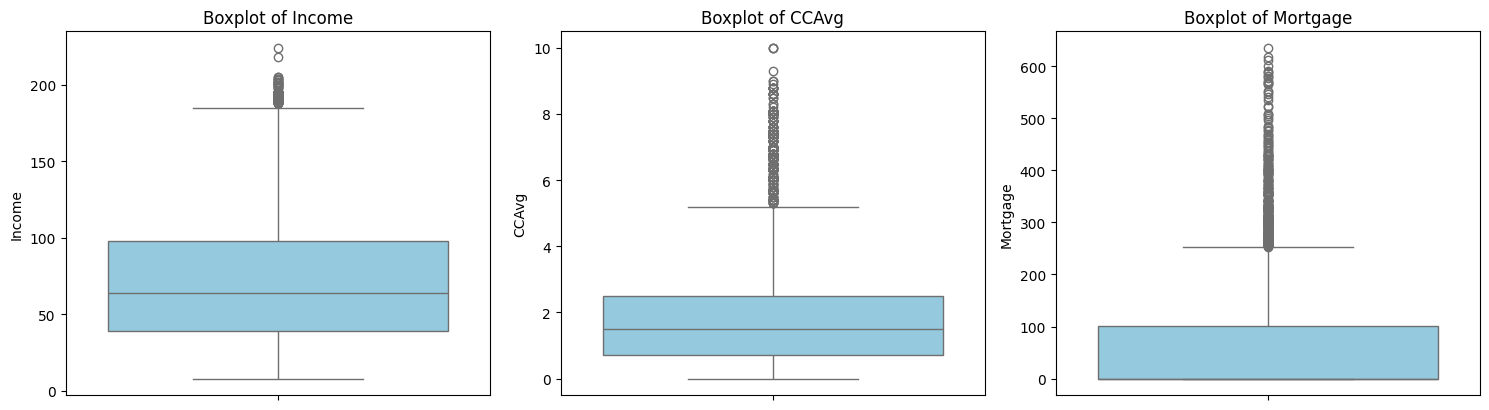

In [ ]:
#look at the columns that we have deemed important, and look for outliers within them; Income, CCAvg and Mortgage
important_cols = ['Income', 'CCAvg', 'Mortgage']
plt.figure(figsize=(15, 8))
for i, col in enumerate(important_cols):
    if col in df.columns:
        plt.subplot(2, 3, i + 1)
        sns.boxplot(y=df[col], color="skyblue")
        plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

So the three: Mortgage, Income and CCAvg have outliers, so we will need to top them off (normalize) after we split the data.

**Preparing Data for Modeling**

We will need to import the sklearn librarys, and then:
1. Data Cleaning and Imputation - we will remove the unneeded columns ZIPCode and ID,
2. We will impute the negatives in Experience, and then Normalize our outliers Income, CCAvg and Mortgage using IQR.
3. Encode our Eduction column
4. Drop our target variable and split up for training
5. We will apply SMOTE (Synthetic Minority Over-sampling Technique) on the data, as the data. SMOTE will balance the datasets and ensure realistic data. SMOTE also gives us the benefit of not having to balance the data during our model building as it already is.




In [ ]:
#import librarys we will need:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
scaler = StandardScaler()

In [ ]:
#Data Cleaning and Imputation:
# Drop unnecessary identifier columns ID and ZIPCode as these will generate noise
df.drop(columns=['ID', 'ZIPCode'], errors='ignore', inplace=True)

# Impute negative Experience values before processing
df['Experience'] = df['Experience'].apply(lambda x: np.nan if x < 0 else x)
df['Experience'] = df['Experience'].fillna(df['Experience'].median())

# Cap Outliers using IQR method on the three important features
important_cols = ['Income', 'CCAvg', 'Mortgage']
for col in important_cols:
    if col in df.columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
        df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])

# One-Hot Encode Education to break it into numeric columns
df_encoded = pd.get_dummies(df, columns=['Education'], drop_first=True, dtype=int)


In [ ]:
#we will drop Personal Loan as this is our target variable
target_col = 'Personal_Loan'
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

# Split clean dataset to 70/30
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=1, stratify=y)

# Initialize scaler and fit on cleanly separated columns
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)


In [ ]:
#Now use SMOTE to balance everything
smote = SMOTE(random_state=1)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train)

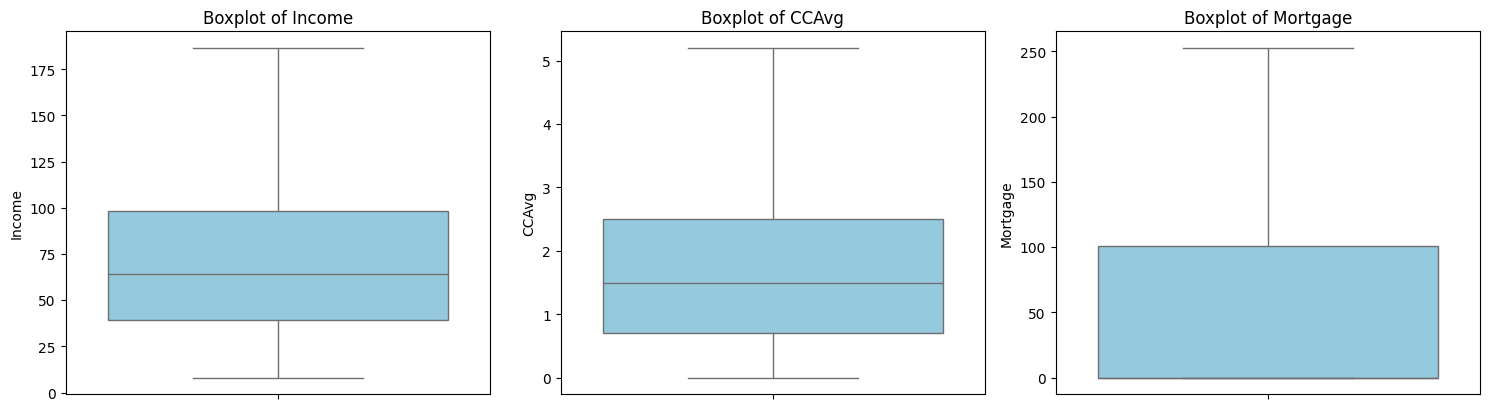

In [ ]:
#Re-run box plots to prove IQR worked:
plt.figure(figsize=(15, 8))
for i, col in enumerate(important_cols):
    if col in df.columns:
        plt.subplot(2, 3, i + 1)
        sns.boxplot(y=df[col], color="skyblue")
        plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

**Any Other Pre-Processing Steps**

We applied SMOTE (Synthetic Minority Over-sampling Technique) on the data, as the data. SMOTE will balance the datasets and ensure realistic data.  

SMOTE also gives us the benefit of not having to balance the data during our model building as it already is.

Finally, a final sanity check to make sure there are no missing records.

In [ ]:
#Re-Confirm there are no missing values:
print(df.isna().sum())
print(df.isnull().sum())

Age                   0
Experience            0
Income                0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
dtype: int64
Age                   0
Experience            0
Income                0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
dtype: int64


## Model Building

### Model Evaluation Criterion

Our Model needs to predict the bank customers who will accept a peronal loan that is offered.

We must be careful **NOT** to:
1. State that a customer will accept a personal loan when they will not (False Positive - and we will waste money campaigning to these people)
2. Predict a customer as one who would reject a personal loan, but who would ultimately accept the personal loan (False Negative - and we will lose out on the business they people would bring in).

We will show five different models, first a Logistic Regression for a baseline model, and then a base Decision Tree, a pre-pruned Decision Tree and then a post-pruned Decision Tree

We will then tune it with GridSearchCV and review the results of this tuned tree.

A confusion matrix, underneath the tree results, will show the predicted categories against the actual, true categories in the dataset, revealing exactly where the model succeeded and where it became confused. I will just print numbers instead of a graph to save space.



### Model Building

In [ ]:
# Setup main dictionary of models (4 + 1 Tuned)
models = {
    "Logistic Regression": LogisticRegression(random_state=1, max_iter=1000),
    "Decision Tree (Base)": DecisionTreeClassifier(random_state=1),
    "Decision Tree (Pre-Pruned)": DecisionTreeClassifier(max_depth=4, min_samples_split=10, min_samples_leaf=5, random_state=1),
    "Decision Tree (Post-Pruned)": DecisionTreeClassifier(ccp_alpha=0.005, random_state=1)
}

# Run optimization using GridSearchCV Decision Tree
param_grid_dt = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
grid_search_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=1),
    param_grid=param_grid_dt,
    scoring='recall',
    cv=5,
    n_jobs=-1
)
grid_search_dt.fit(X_train_balanced, y_train_balanced)

# Add the GridSearchCV optimized tree into evaluation dictionary
models["Decision Tree (GridSearchCV Tuned)"] = grid_search_dt.best_estimator_

print("\n--- FINAL EVALUATION SUMMARY ---")
for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print("\n" + "="*50)
    print(f"MODEL: {name}")
    print("="*50)
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))






--- FINAL EVALUATION SUMMARY ---

MODEL: Logistic Regression
Accuracy:  0.9093
Recall:    0.8403
Precision: 0.5171
F1-Score:  0.6402

Confusion Matrix:
 [[1243  113]
 [  23  121]]

MODEL: Decision Tree (Base)
Accuracy:  0.9800
Recall:    0.8958
Precision: 0.8958
F1-Score:  0.8958

Confusion Matrix:
 [[1341   15]
 [  15  129]]

MODEL: Decision Tree (Pre-Pruned)
Accuracy:  0.9720
Recall:    0.8958
Precision: 0.8269
F1-Score:  0.8600

Confusion Matrix:
 [[1329   27]
 [  15  129]]

MODEL: Decision Tree (Post-Pruned)
Accuracy:  0.9480
Recall:    0.8611
Precision: 0.6813
F1-Score:  0.7607

Confusion Matrix:
 [[1298   58]
 [  20  124]]

MODEL: Decision Tree (GridSearchCV Tuned)
Accuracy:  0.9673
Recall:    0.9236
Precision: 0.7778
F1-Score:  0.8444

Confusion Matrix:
 [[1318   38]
 [  11  133]]


Logistic Regression has 90.93% accuracy and 82.64% recall that gives us a baseline. Logistic Regression precision will flag nearly half as false.

We created a base standard decision tree also for comparision purposes against an unpruned and a post pruned tree.

The base decision tree has the highest accuracy, recall and F1 score as expected, and possibly overfitting of the data.

The pre-pruned tree came back with the best accuracy against the post pruned tree (as it splits everything up to my set limits).

The post-pruned tree grew to its maximum size, and then the ccp_alpha audits it back and gives optimized balance. We can see that the numbers are generalized.

The GridSearchCV tuned tree has a good F-1 score, recall and accuracy.



## Model Performance Improvement

We want to improve the performance, so we will use the Random Forest to run through a number of decision trees. Random Forest will smooth out variance if we have overfitting. We will see our results from a forest of decision trees, and then tune to further refine leverage XGBClassifier to help boost. We will then compare all the results to determine the best method.

In [ ]:
#Use Ensemble Method to further refine and XGBClassifier  to help boost
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, recall_score

#Train 100 different variants of the decision tree, use XGBoost to help with corrections
#We do not need to add  class_weight='balanced' to Random Forest as SMOTE has done this
ensemble_models = {
    "Random Forest (Tuned Baseline)": RandomForestClassifier(
        n_estimators=100, max_depth=7, random_state=1
    ),
    "XGBoost Classifier": XGBClassifier(
        n_estimators=100, max_depth=5, learning_rate=0.1, random_state=1, eval_metric='logloss'
    )
}

# 2. Train and Evaluate Ensembles
for name, model in ensemble_models.items():
    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test_scaled)

    print("\n" + "="*40)
    print(f" ENSEMBLE MODEL: {name} ")
    print("="*40)
    print(f"Test Recall Score: {recall_score(y_test, y_pred):.4f}")
    print("\nFull Classification Report:\n", classification_report(y_test, y_pred))



 ENSEMBLE MODEL: Random Forest (Tuned Baseline) 
Test Recall Score: 0.9306

Full Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.98      0.99      1356
           1       0.84      0.93      0.88       144

    accuracy                           0.98      1500
   macro avg       0.92      0.96      0.93      1500
weighted avg       0.98      0.98      0.98      1500


 ENSEMBLE MODEL: XGBoost Classifier 
Test Recall Score: 0.9167

Full Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      1356
           1       0.91      0.92      0.91       144

    accuracy                           0.98      1500
   macro avg       0.95      0.95      0.95      1500
weighted avg       0.98      0.98      0.98      1500



The XGBoost Recall at 0.9167 means we are catch 91.7% of all potential loan buyers, which means we won't be wasting money calling the wrong people

Now lets look at the importance of each variable versus the personal loan which we will need for our analysis and review.

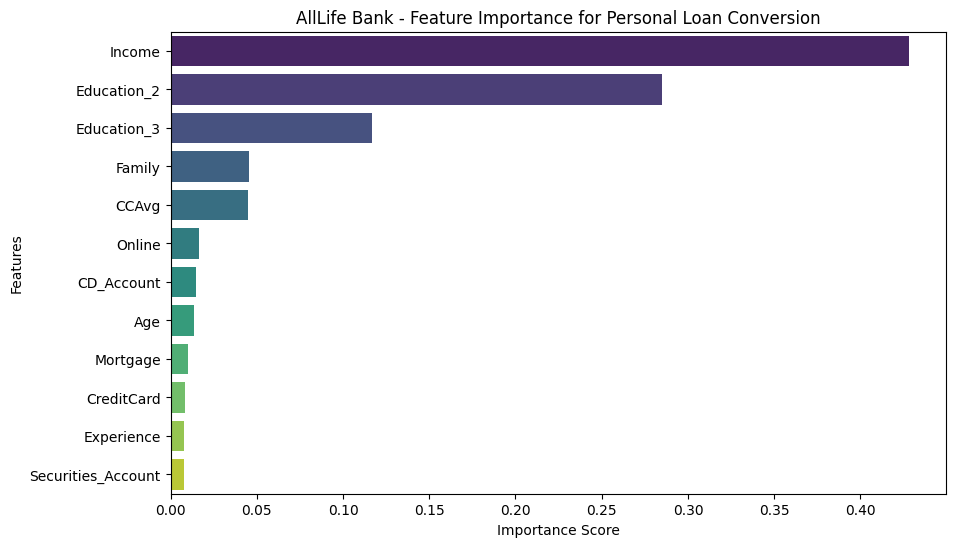

In [ ]:
# Extract feature importance from the trained model
importances = ensemble_models["XGBoost Classifier"].feature_importances_
feature_names = X_train.columns

# Create a clean DataFrame sorted by importance
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# Plot the top features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis', hue='Feature')
plt.title('AllLife Bank - Feature Importance for Personal Loan Conversion')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()


This graph shows the impact that each customer trait has on whether a customer will accept a personal loan

We can see that Income, CCAvg and Education are the three most important ones.

## Model Performance Comparison and Final Model Selection

To improve performance we should pull in a Random Forest method (which is being taught in the advanced machine learning modules that I have begun studying).

The random forest will select from a multiple range of decision trees (forest) and come up with the best one. We will then use XGBoost Classifier (Extreme Gradient Boosting) on the trees, to give us a best tuned model.

To compare the models, we will need to obtain the training values for reference and to add them to our summary. So first print them out.

In [ ]:
#We have all the results printed except for the Train Recall values, so get them here:
log_train_rec = recall_score(y_train_balanced, models["Logistic Regression"].predict(X_train_balanced))
dt_train_rec = recall_score(y_train_balanced, models["Decision Tree (Base)"].predict(X_train_balanced))
dtpre_train_rec = recall_score(y_train_balanced, models["Decision Tree (Pre-Pruned)"].predict(X_train_balanced))
dtpost_train_rec = recall_score(y_train_balanced, models["Decision Tree (Post-Pruned)"].predict(X_train_balanced))
dtgrid_train_rec = recall_score(y_train_balanced, models["Decision Tree (GridSearchCV Tuned)"].predict(X_train_balanced))
rf_train_rec = recall_score(y_train_balanced, ensemble_models["Random Forest (Tuned Baseline)"].predict(X_train_balanced))
xgb_train_rec = recall_score(y_train_balanced.astype(int), ensemble_models["XGBoost Classifier"].predict(X_train_balanced))

# Print them out so we can use them in the next block of code:
print(f"Logistic Regression Train Recall: {log_train_rec:.4f}")
print(f"DecisionTree Base Train Recall:   {dt_train_rec:.4f}")
print(f"DecisionTree Pre-P Train Recall:  {dtpre_train_rec:.4f}")
print(f"DecisionTree Post-P Train Recall: {dtpost_train_rec:.4f}")
print(f"DecisionTree Grid Train Recall:   {dtgrid_train_rec:.4f}")
print(f"Random Forest Train Recall:       {rf_train_rec:.4f}")
print(f"XGBoost Classifier Train Recall:  {xgb_train_rec:.4f}")

Logistic Regression Train Recall: 0.9327
DecisionTree Base Train Recall:   1.0000
DecisionTree Pre-P Train Recall:  0.9738
DecisionTree Post-P Train Recall: 0.9697
DecisionTree Grid Train Recall:   0.9905
Random Forest Train Recall:       0.9962
XGBoost Classifier Train Recall:  0.9997


In [ ]:
# make one comparsion variable chart and manually enter the results.
# note: if this were an actual production - would have saved the results and used that to import instead of manually typing here
comparison_metrics = {
    "Model Name": [
        "Logistic Regression (Baseline)",
        "Decision Tree (Base)",
        "Decision Tree (Pre-Pruned)",
        "Decision Tree (Post-Pruned)",
        "Decision Tree (GridSearchCV Tuned)",
        "Random Forest Ensemble",
        "XGBoost Classifier"
    ],
    "Train Recall": [0.9327, 1.0000, 0.9738, 0.9697, 0.9905, 0.9962, 0.9997],
    "Test Recall": [0.8403, 0.8958, 0.8958, 0.8611, 0.9236, 0.9306, 0.9167],
    "Test Precision": [0.5171, 0.8958, 0.8269, 0.6813, 0.7778, 0.84, 0.91],
    "Test F1-Score": [0.6402, 0.8958, 0.86, 0.7607, 0.8444, 0.88, 0.91]
}

# Convert to DataFrame
df_comparison = pd.DataFrame(comparison_metrics)

# Display the comparison table sorted by our primary metric: Test F1-Score
print("="*65)
print("             Model Comparison")
print("="*65)
print(df_comparison.sort_values(by="Test F1-Score", ascending=False).to_string(index=False))
print("="*65)


             Model Comparison
                        Model Name  Train Recall  Test Recall  Test Precision  Test F1-Score
                XGBoost Classifier        0.9997       0.9167          0.9100         0.9100
              Decision Tree (Base)        1.0000       0.8958          0.8958         0.8958
            Random Forest Ensemble        0.9962       0.9306          0.8400         0.8800
        Decision Tree (Pre-Pruned)        0.9738       0.8958          0.8269         0.8600
Decision Tree (GridSearchCV Tuned)        0.9905       0.9236          0.7778         0.8444
       Decision Tree (Post-Pruned)        0.9697       0.8611          0.6813         0.7607
    Logistic Regression (Baseline)        0.9327       0.8403          0.5171         0.6402


## Actionable Insights and Business Recommendations


**Final Model Selection and Justification**

My goal is to maximize personal loan conversion rates for AllLife Bank while minimizing marketing costs.

From this point of view, the XGBoost Classifier is the recommended model for deployment. It achieved the highest overall balance, capturing 91.67% of all actual loan buyers (Recall) while maintaining a 91% accuracy rate on those positive predictions (Precision). It lifts the F1-Score from 0.64 with the baseline logisitic regression to 0.91, so that we are focusing on the best prospects.

The XGBoost is the clear winner in terms of handling the data and making solid predictions. The test set had 144 people who accepted the personal loan, and with .9167 accuracy, XGBoost identifies 132 of them. XGBoost will give fewer false positive errors, which is what we are looking for.

Based on the results:

Primary Metric - F1-Score:
XGBoost achieved a 0.91 F1-score, proving an exceptional, near-perfect balance between maximizing buyer detection and eliminating marketing waste

Secondary Metric - Test Precision:
Again XGBoost beat the others and came in at 91% which means that we have minimized the non-viable clients to market to.

From the **decision trees**, the best one is the Decision Tree (GridSearchCV Tuned) model. While the Base Decision Tree scores higher in Precision, it is completely overfitted (100% Train Recall vs. 89.58% Test Recall).

The GridSearchCV Tuned tree successfully controls variance and achieves the highest Test Recall (92.36%) among all stand-alone tree models.

For AllLife Bank's objective of finding as many potential loan buyers as possible, it stands out as the top non-ensemble performer.

The Decision Tree (Base) achieved a perfect 1.0000 Train Recall. But this is textbook overfitting.

The GridSearchCV Tuned tree had great recall, catching 133 out of the 144 buyers.

Random Forest has a higher recall score than XGBoost, however, the precision is lower.


* What recommedations would you suggest to the bank?

My recommendation to the bank is to implement the Boosting Method via the tuned XGBoost Classifier. By deploying this model, AllLife Bank can market to a highly tuned and precise data group. The business can confidently expect an optimized conversion rate on its cross-selling campaigns while maintaining a predictable marketing budget.

For non-ensemble choice, the GridSearchCV Tuned Tree is the best selection.

**ACTIONABLE INSIGHTS AND RECOMMENDATIONS:**

Based on the EDA (exploratory data analysis) and the model tests given, the following recommendations are proposed for the next Personal Loan campaign.

**INSIGHTS:**
1. High Income: The strongest predictor, which is shown in our "AllLife Bank - Feature Importance for Personal Loan Conversion" map. There is a larger conversion rate with the high income people, which probably means they are using these loans for other purposes rather than as safety nets or settling other troubled debts.

2. Credit Card Spending: This is the second highest predictor, so people with a high credit card spend means they are more receptive to a personal loan. This probably means that they wish to restructure the short term high interest debt into a longer term with lower interest.

3. Education: The third highest predictor are customers with higher levels of eduction, which show a more likelyhood of accepting the personal loan offer. The meaning of this is most likely due to a better understanding of interest rates and managing their money, budgets.

4. The data shows us that customer age, family size, mortgage and having credit cards is negligable as a predictor for selecting a personal loan.


**BUSINESS RECOMMENDATIONS (Next Steps):**

1. Target high income customers with higher eduction
-Segment the marketing campaign to focus on customers with higher incomes with higher eduction. By doing so, it will reduce marketing costs (as compared with targeting the entire data set) and provide a higher degree of acceptance per customer targeted.

2. Target customers with a high credit card spend with higher education
-Segmenting out the customers this way will allow the customer to see the benefit with a long term personal loan versus the short term credit card spend.

2b. Target customers with just a high credit card spend with minimum eduction (Level 1)
-For this segment, use a lower cost marketing campaign to target the people in this group. Because they have a lower acceptance rate, create beginning or entry level products to entice them.  

3. For any campaigns that may be targeting the negligable segments (family size, age, mortgage)
-Begin to phase these out, as they are shown to not be good acceptance groups.



___

In [ ]:
!jupyter nbconvert --to html '/content/drive/MyDrive/Colab Notebooks/AIML_ML_Project_Full_Code_Notebook.ipynb'

[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/AIML_ML_Project_Full_Code_Notebook.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 17 image(s).
[NbConvertApp] Writing 1095409 bytes to /content/drive/MyDrive/Colab Notebooks/AIML_ML_Project_Full_Code_Notebook.html
